# 06 — Baseline models

Two simple models every later model must beat, scored on the **validation** cohorts:

1. **Always the average** (`DummyClassifier`): gives every business the training failure rate. This is the floor.
2. **Logistic regression**: a straight-line model. Simple, fast and easy to explain, so it is the real baseline.

**Reads:** `pipeline/05_model_table.parquet`, `05_features.json`.  **Saves:** `pipeline/06_baseline_results.csv`.
The test set is **not** touched here.

**Scores** (same code for every model, `ml/src/model_tools.py`), with **failed** as the class to catch:

| Score | Meaning | Better |
|---|---|---|
| PR-AUC | how well failed businesses are ranked above survived ones, focused on the rare class | higher (floor = failure rate) |
| ROC-AUC | the chance a failed business gets a higher risk than a survived one | higher (0.5 = guessing) |
| recall (failed) | of the businesses that failed, the share the model flagged (risk ≥ 0.5) | higher |
| precision (failed) | of the businesses flagged, the share that really failed | higher |
| Brier | average squared error of the predicted chance | lower |

**The notebooks, in order** (each one loads what the one before saved, so nothing is downloaded or read from Excel twice):

| # | Notebook | Saves (in `Darb DataSets/pipeline`) |
|---|---|---|
| 00 | `00_download` | `00_raw/`: an exact copy of every raw file, as fast parquet |
| 01 | `01_eda_raw` | `01_quarter_quality.csv`: how complete each MC quarter is |
| 02 | `02_preprocess_businesses` | `02_businesses.parquet`: one row per business, with its label |
| 03 | `03_preprocess_economic` | `03_*.parquet`: GDP, SME, SAMA and licensing features |
| 04 | `04_eda_clean` | nothing (looks only) |
| 05 | `05_features` | `05_model_table.parquet`: the model's inputs and the time split |
| 06 | `06_baseline` | `06_baseline_results.csv` |
| 07 | `07_tuning` | `07_best_params.json`, `07_tuning_results.csv` |
| 08 | `08_final_training` | `models/`: the final model and its report |

**Rules:** raw files are never changed · nothing is dropped (problems get a flag) · data never goes into Git ·
clear all outputs before committing.

### Setup
Finds the data folder. **Locally** it is `~/darb-data` (or the folder in the `DARB_DATA` setting), a copy of the
team's Drive folder **Darb DataSets**. **On Colab** it is Darb DataSets itself: add a shortcut to it in your My
Drive first, and upload the files of `ml/src` to `/content`.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    !pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from model_tools import fis, fis_band, make_model, make_preprocessor, scores

table = pd.read_parquet(need(PIPE / '05_model_table.parquet', '05_features'))
spec = json.loads((PIPE / '05_features.json').read_text())
CATEGORICAL, NUMERIC, TARGET = spec['categorical'], spec['numeric'], spec['target']
INPUTS = CATEGORICAL + NUMERIC
for column in CATEGORICAL:
    table[column] = table[column].astype(object).where(table[column].notna(), np.nan)
parts = {name: table[table['split'] == name] for name in ['train', 'validation', 'test']}
X = {name: part[INPUTS] for name, part in parts.items()}
y = {name: part[TARGET].to_numpy() for name, part in parts.items()}
pd.set_option('display.width', 200)
print({name: f'{len(part):,} rows, {y[name].mean():.1%} failed' for name, part in parts.items()})

{'train': '89,800 rows, 17.2% failed', 'validation': '93,949 rows, 8.5% failed', 'test': '76,547 rows, 12.3% failed'}


## 1 — Always the average

In [3]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='prior').fit(X['train'], y['train'])
results = {'always the average': scores(y['validation'], dummy.predict_proba(X['validation'])[:, 1])}
pd.DataFrame(results).T.round(4)

,PR-AUC,ROC-AUC,recall (failed),precision (failed),Brier,failure rate
always the average,0.085,0.5,0.0,0.0,0.0853,0.085


## 2 — Logistic regression
Inputs are prepared the same way for every model (`make_preprocessor`): empty numbers → the median (plus a column
saying it was empty), numbers scaled, categories → one column per value (values seen fewer than 200 times share an
"infrequent" column). `class_weight='balanced'` gives the rare failed businesses the same total weight as the
survived ones, so the model does not just say "survives" for everyone.

In [4]:
from sklearn.linear_model import LogisticRegression

logreg = make_model(make_preprocessor(NUMERIC, CATEGORICAL, scale_numbers=True),
                    LogisticRegression(class_weight='balanced', max_iter=3000))
logreg.fit(X['train'], y['train'])
p_val = logreg.predict_proba(X['validation'])[:, 1]
results['logistic regression'] = scores(y['validation'], p_val)
baseline = pd.DataFrame(results).T
baseline.round(4)

,PR-AUC,ROC-AUC,recall (failed),precision (failed),Brier,failure rate
always the average,0.0850,0.5000,0.0000,0.0000,0.0853,0.085
logistic regression,0.1886,0.7696,0.7065,0.1719,0.1430,0.085


### What the logistic regression learned
The 15 inputs that push the risk of failing up (positive) or down (negative) the most. Numbers are scaled, so
their sizes can be compared.

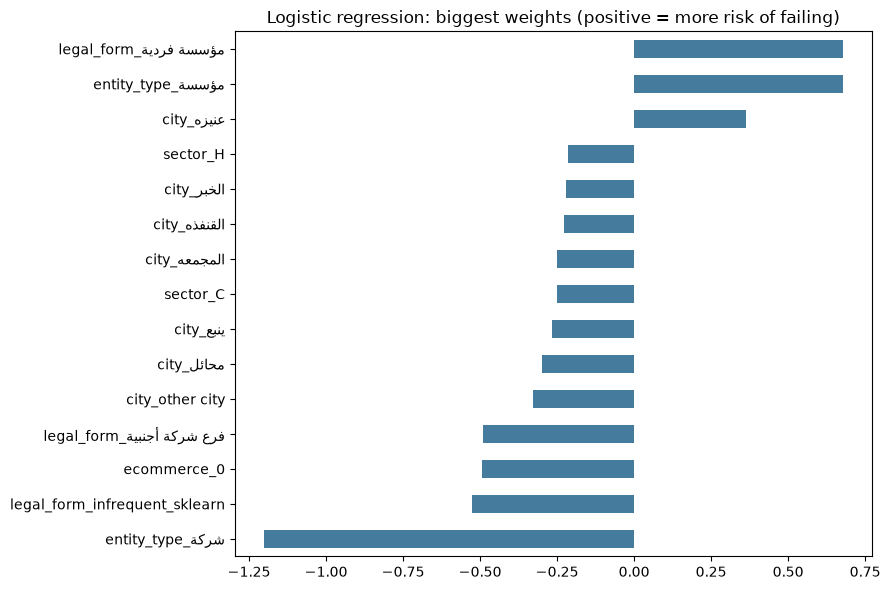

In [5]:
names = logreg.named_steps['prepare'].get_feature_names_out()
weights = pd.Series(logreg.named_steps['model'].coef_[0], index=names)
top = weights.reindex(weights.abs().sort_values(ascending=False).index).head(15)
top.sort_values().plot.barh(title='Logistic regression: biggest weights (positive = more risk of failing)', figsize=(9, 6), color='#457b9d')
plt.tight_layout(); plt.show()

### Precision and recall at every threshold (validation)

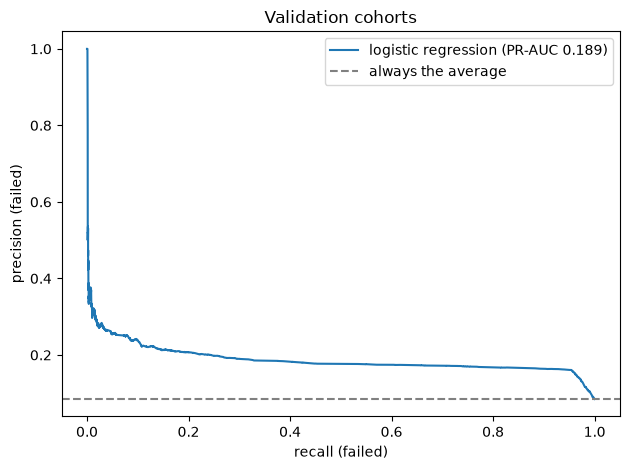

In [6]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y['validation'], p_val)
plt.plot(recall, precision, label=f'logistic regression (PR-AUC {results["logistic regression"]["PR-AUC"]:.3f})')
plt.axhline(y['validation'].mean(), color='grey', ls='--', label='always the average')
plt.xlabel('recall (failed)'); plt.ylabel('precision (failed)'); plt.legend(); plt.title('Validation cohorts')
plt.tight_layout(); plt.show()

## Save

In [7]:
baseline.to_csv(PIPE / '06_baseline_results.csv', index_label='model')
print('Saved', PIPE / '06_baseline_results.csv')

Saved /Users/halaalsabbar/darb-data/pipeline/06_baseline_results.csv
